<h1>Разработка A/B-тестирования и анализ результатов</h1>

<h3>Цель:</h3>
<p>
Оценить, стоит ли внедрять для всех пользователей новый алгоритм рекомендаций в приложении с лентой видео. Команда Data Science считает, что новый алгоритм, учитывающий персональные интересы пользователя, увеличит глубину просмотра <code>page_counter</code> и удержание. Нужно спроектировать дизайн A/B-теста, рассчитать его параметры на исторических данных, проверить корректность проведения эксперимента и вынести вердикт по его результатам.</p>
<h3>Контекст:</h3>
<p>
Приложение монетизируется через рекламу (бесплатный доступ) и платную подписку без рекламы. Релевантный контент должен увеличивать время в приложении, есть два основных риска: пользователи без подписки могут негативно реагировать на рекламные вставки, ценность подписки без рекламы может снизиться</p>

<h3>Данные:</h3>
<ul>
    <li><code>sessions_project_history.csv</code> — исторические данные по сессиям с 2025-08-11 по 2025-09-23</li>
    <li><code>sessions_project_test_part.csv</code> — данные за первый день A/B-теста (2025-10-14)</li>
    <li><code>sessions_project_test.csv</code> — данные за весь период A/B-теста (2025-10-14 – 2025-11-02)</li>
</ul>

<h3>Основная метрика:</h3>
<p>Доля успешных первых сессий — первых сессий пользователя, в которых просмотрено не менее 4 страниц (<code>page_counter >= 4</code>).</p>
<h3>План работы</h3>
<ul>
    <li>Этап 1 Подготовка среды: загрузка данных, фиксация random_state, установка библиотек</li>
    <li>Этап 2 Анализ данных (EDA): работа с историческими данными, анализ числа первых сессий, числа просмотренных страниц и доли успешных первых сессий</li>
    <li>Этап 3 Подготовка к тесту: расчёт размера выборки и длительности A/B-теста</li>
    <li>Этап 4 Мониторинг A/B-теста: проверка распределения пользователей по группам, пересечений, устройствам и регионам</li>
    <li>Этап 5 Проверка результатов A/B-теста: формулировка гипотез, сравнение доли успешных сессий, z-тест, итоговый вывод и рекомендация</li>
</ul>

<h2>Этап 1 Подготовка среды: загрузка данных, фиксация random_state, установка библиотек</h2>

In [1]:
import os
import time
from math import ceil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

<h3>Зафиксируем <code>random_state</code> и параметры отображения</h3>

In [2]:
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12

RANDOM_STATE = 42

<h3>Выгрузим данные:</h3>

In [3]:
try:
    sessions_history = pd.read_csv('sessions_project_history.csv')
    sessions_test_part = pd.read_csv('sessions_project_test_part.csv')
    sessions_test = pd.read_csv('sessions_project_test.csv')
except:
    sessions_history = pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_history.csv')
    sessions_test_part = pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_test_part.csv')
    sessions_test = pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_test.csv')

datasets = {
    'sessions_history': sessions_history,
    'sessions_test_part': sessions_test_part,
    'sessions_test': sessions_test,
}

for name, df in datasets.items():
    print(f'{name}: {df.shape}')

sessions_history: (435924, 10)
sessions_test_part: (3130, 11)
sessions_test: (100005, 11)


<p><b>Среда разработки поготовлена, данные выгружены. Переходим к EDA </b></p>

<h2>Этап 2. Анализ данных (EDA) работа с историческими данными </h2>

<h3>Знакомство с данными</h3>

In [4]:
session_counts = sessions_history.groupby('user_id')['session_id'].nunique().sort_values(ascending=False)
top_user = session_counts.index[0]
print()
print(f"Пользователь с максимальным количеством сессий\n"
      f"ID: {top_user}\n"
      f"Количество сессий {session_counts.iloc[0]}")
display(sessions_history[sessions_history["user_id"]==top_user])


Пользователь с максимальным количеством сессий
ID: 10E0DEFC1ABDBBE0
Количество сессий 10


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


<b>Максимальное количество сессий для одного пользователя 10</b>
<ul>
    <li>Найденное количество ссейсий не выглядит аномальным</li>
    <li>Стобцы соответствуют исходной информации о датасетах</li>
    <li>Рассматриваемый пользователь так и остался не зарегестрированным, несмотря на максимальное количество сессий, если брать количество регестраций как метрику стоит рассмотреть этих пользователей подробней</li>
    <li>Датасет состоит из столбцов которые определяются в момент начала сессии в момент конца сессии и постоянных признаков дл клиента</li>
    <ul>Признаки создаваемые при начале сессии
        <li><code>session_id</code></li>
        <li><code>session_date</code></li>
        <li><code>session_start_ts</code></li>
        <li><code>session_number</code></li>
        <li><code>device</code></li>
    </ul>
    <ul>Признаки создаваемые при окончании сессии
        <li><code>page_counter</code></li> 
    </ul>
    <ul>Постоянные признаки клиента
        <li><code>user_id</code></li>
        <li><code>install_date</code></li>
        <li><code>region</code></li>
        <li><code>registration_flag</code></li>
    </ul>
    <li>Основная цель признак <code>page_counter</code> гипотеза новая модель увеличивает удержание</li>
    <li>Стоит так же рассмотреть меняется ли <code>device</code> и <code>region</code> у одного пользователя</li>
</ul>

Рассмотрим уникальность признаков <code>device</code> и <code>region</code> для 1 пользователя 

In [5]:
print("Пользователей у которых менялось устройство", (sessions_history.groupby('user_id')['device'].nunique() > 1).sum())
print("Пользователей у которых менялся регион", (sessions_history.groupby('user_id')['region'].nunique() > 1).sum())

Пользователей у которых менялось устройство 0
Пользователей у которых менялся регион 0


Таких пользователей нет

<h3>Анализ числа регистраций</h3>

In [6]:
sessions_history["session_date"] = pd.to_datetime(sessions_history["session_date"])

Приобразуем дату в datetime

In [7]:
users = sessions_history.groupby('session_date')['user_id'].nunique()
registered = sessions_history.groupby('session_date')['registration_flag'].sum()

daily = pd.DataFrame({'users': users, 'registered': registered})
daily['share'] = daily['registered'] / daily['users']

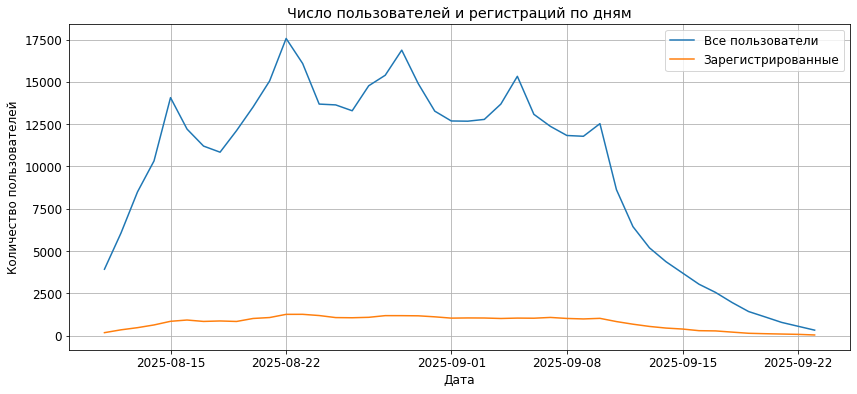

In [8]:
plt.plot(daily.index, daily['users'], label='Все пользователи')
plt.plot(daily.index, daily['registered'], label='Зарегистрированные')
plt.title('Число пользователей и регистраций по дням')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.grid()
plt.legend()
plt.show()

<b>Анализ числа регистраций дал новую информацию:</b>
<p>В последние дни не было роста числа зарегестрированных пользователей было лишь сильное снижении числа активных пользователей, поэтому подсчет доли может получится искаженно оптимистичным, судя по данным в абсолютных значениях</p>

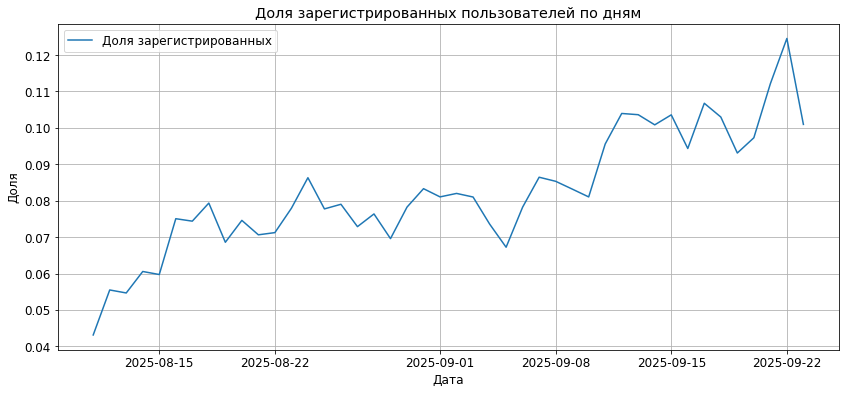

In [9]:
plt.plot(daily.index, daily['share'], label='Доля зарегистрированных')
plt.title('Доля зарегистрированных пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Доля')
plt.grid()
plt.legend()
plt.show()

<b>Анализ доли подтвердил размышления выше</b>
<p>В последние дни наблюдений замечен явный рост, доли зарегестрированных пользователей, однако в абсолютных значениях это объясняется лишь снижением знаменателя(общего числа пользователей), реального улучшения нет</p>

<h3>Анализ числа просмотренных страниц</h3>

/opt/conda/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


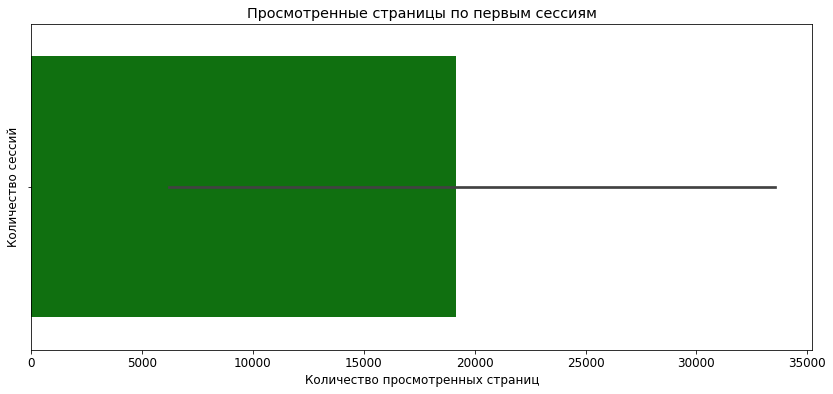

In [10]:
first_session_bypage = sessions_history[sessions_history['session_number'] == 1].groupby('page_counter')['session_id'].count()
sns.barplot(first_session_bypage, color='green')
plt.xlabel('Количество просмотренных страниц')
plt.ylabel('Количество сессий')
plt.title("Просмотренные страницы по первым сессиям")
plt.show()

<b>Анализ числа просмотренных страниц</b>
<p>Распределение имеет колокообразный вид с пиком в 3 просмотренных страницах, если критерий успеха 4 и более стоит обратить внимание на сдвиг пика распределения ближе к 4</p>

<h3>Доля пользователей, просмотревших более четырёх страниц</h3>

In [11]:
sessions_history["good_session"] = sessions_history["page_counter"] >= 4

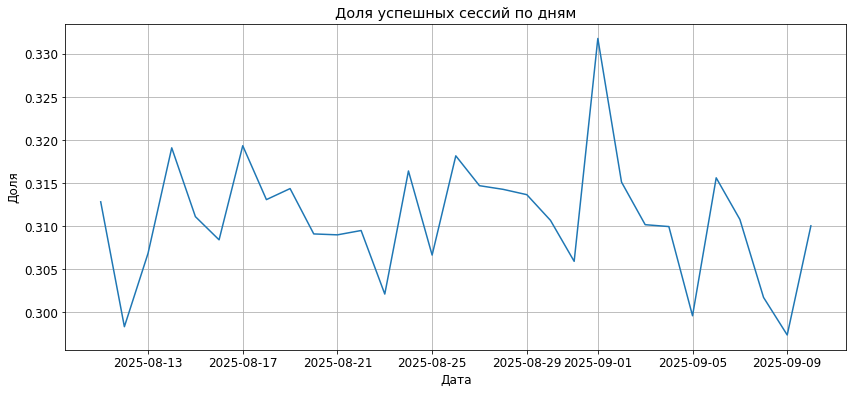

In [12]:
good_session_share = sessions_history[sessions_history['session_number'] == 1].groupby("session_date")['good_session'].mean()
plt.plot(good_session_share)
plt.title('Доля успешных сессий по дням')
plt.xlabel('Дата')
plt.ylabel('Доля')
plt.grid()
plt.show()

<b>Анализ доли пользователей, просмотревших более четырёх страниц</b>
<p>Доля пользователей с просмотром более 4 страниц колеблется от 0.286 до 0.335, пик 2025-09-01 наблюдается хаотичное изменение доли есть как явно  выраженные пики так и спады нет четкой времянной зависимоти стоит связать долю с маркетинговыми кампаниями и датами их проведения</p>

<h2>Подготовка к тесту</h2>

<h3> Расчёт размера выборки</h3>

In [13]:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода
power = 1 - beta  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.03 * p  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1
)

print(f"Размер выборки для одной группы: {sample_size}")

Размер выборки для одной группы: 41040.69255118558


<h3>Расчёт длительности A/B-теста</h3>

In [14]:
avg_daily_users = sessions_history.groupby('session_date')['user_id'].nunique().mean()
test_duration = ceil(sample_size * 2 / avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при {avg_daily_users:.0f} пользователях/день: {test_duration} дней")

Рассчитанная длительность A/B-теста при 9907 пользователях/день: 9 дней


<h2>Мониторинг А/В-теста</h2>

<h3>Проверка распределения пользователей</h3>

In [15]:
gr_a = sessions_test_part[sessions_test_part['test_group'] == 'A']
gr_b = sessions_test_part[sessions_test_part['test_group'] == 'B']

users_a = gr_a['user_id'].nunique()
users_b = gr_b['user_id'].nunique()

print(f"Строк в группе A: {len(gr_a)} B: {len(gr_b)}\n"
      f"Уникальных пользователей в группе A: {users_a}\n"
      f"Уникальных пользователей в группе B: {users_b}")


Строк в группе A: 1502 B: 1628
Уникальных пользователей в группе A: 1477
Уникальных пользователей в группе B: 1466


In [16]:
diff = 100 * abs(users_a - users_b) / users_a
print("Разница в количестве пользователей:", diff)

Разница в количестве пользователей: 0.7447528774542993


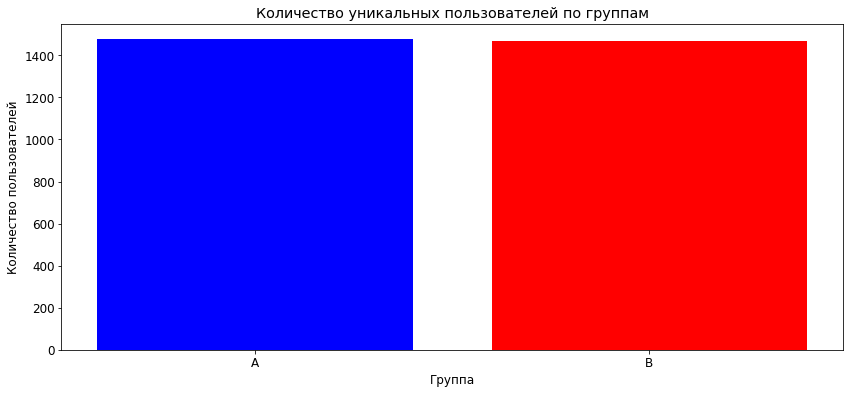

In [17]:
plt.bar(['A', 'B'], [users_a, users_b], color=['blue', 'red'])
plt.title('Количество уникальных пользователей по группам')
plt.xlabel('Группа')
plt.ylabel('Количество пользователей')
plt.show()

<p>
<b>Вывод</b>
В группе A 1477 уникальных пользователей, в группе B 1466. Разница составляет около 0,74% группы практически равны в размерах
</p>

<h3>Проверка пересечений пользователей</h3>

In [18]:
users_a_un = gr_a['user_id'].drop_duplicates()
users_b_un = gr_b['user_id'].drop_duplicates()

intersection = users_a_un.isin(users_b_un).sum()
print("Пользователей, попавших в обе группы:", intersection)

Пользователей, попавших в обе группы: 0


<p>
    <b>Вывод</b>
    Нет пользователей попавших одновременно в A и B. Выборки независимы
</p>

<h3>Равномерность разделения пользователей по устройствам</h3>

/tmp/ipykernel_694/4065125391.py:5: MatplotlibDeprecationWarning: normalize=None does not normalize if the sum is less than 1 but this behavior is deprecated since 3.3 until two minor releases later. After the deprecation period the default value will be normalize=True. To prevent normalization pass normalize=False 
  axes[0].pie(device_a, labels=device_a.index, autopct='%1.1f%%')


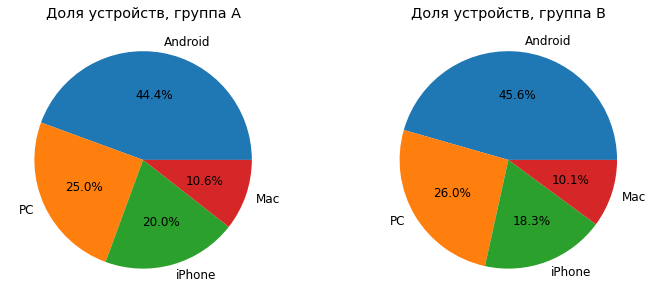

In [19]:
device_a = gr_a.drop_duplicates('user_id')['device'].value_counts() / users_a
device_b = gr_b.drop_duplicates('user_id')['device'].value_counts() / users_b

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].pie(device_a, labels=device_a.index, autopct='%1.1f%%')
axes[0].set_title('Доля устройств, группа A')
axes[1].pie(device_b, labels=device_b.index, autopct='%1.1f%%')
axes[1].set_title('Доля устройств, группа B')
plt.show()

<p>
    <b>Вывод</b>
    Доли устройств в группах A и B практически совпадают Android занимает чуть меньше половины, PC около четверти, iPhone пятую часть, Mac около десятой. Явных различий нет.
</p>

<p>
    <b></b>
</p>

<h3>Равномерность распределения пользователей по регионам</h3>

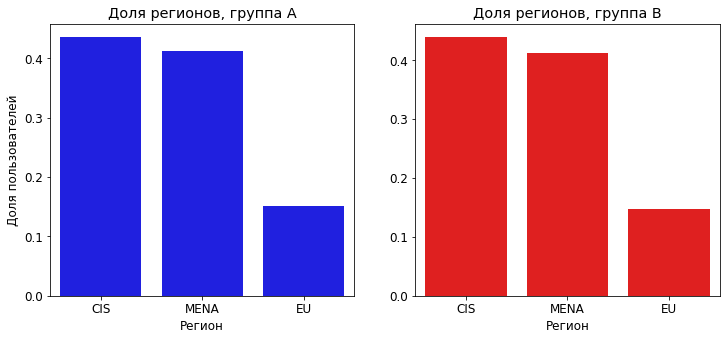

In [20]:
region_a = gr_a.drop_duplicates('user_id')['region'].value_counts() / users_a
region_b = gr_b.drop_duplicates('user_id')['region'].value_counts() / users_b

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=region_a.index, y=region_a.values, ax=axes[0], color='blue')
axes[0].set_title('Доля регионов, группа A')
axes[0].set_xlabel('Регион')
axes[0].set_ylabel('Доля пользователей')
sns.barplot(x=region_b.index, y=region_b.values, ax=axes[1], color='red')
axes[1].set_title('Доля регионов, группа B')
axes[1].set_xlabel('Регион')
plt.show()

<p>
    <b>Вывод</b>
    Доли регионов в группах A и B совпадают, CIS 0.44, MENA 0.41, EU 0.15. Различия между группами не выявлены
</p>

<h3>Вывод после проверки A/B-теста</h3>

<ul>
    <li>Количество пользователей в группах различается на 0,74% - допустимое отклонение</li>
    <li>Пересечений пользователей между группами не обнаружено</li>
    <li>Распределения по устройствам и регионам в группах совпадают</li>
    <li>Нарушений нет. A/B-тест проходит корректно</li>
</ul>

<h2>Проверка результатов A/B-теста</h2>

<h3>Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси и барьерных метрик</h3>

<h4>Определение целевой, прокси и барьерных метрик</h4>
<ul>
<h4>Определение целевой, прокси и барьерных метрик</h4>
<ul>
    <li><b>Целевая метрика</b> доля успешных первых сессий. Успешной считается сессия с <code>page_counter >= 4</code>, доля считается по столбцу <code>good_session</code> среди первых сессий <code>session_number == 1</code></li>
    <li><b>Прокси-метрики</b>
        <ul>
            <li>Средний <code>page_counter</code> за сессию - более детальный обзор вовлечённости без учёта порога в 4 страницы.</li>
            <li>Доля пользователей, имеющих вторую сессию, и время до неё - показывает удержание клиента</li>
            <li>Средний <code>page_counter</code> по группам номера сессий - показывает, сохраняется ли вовлечённость с учетом опыта</li>
        </ul>
    </li>
    <li><b>Барьерные метрики</b>
        <ul>
            <li>Доля закрытий приложения сразу после рекламной вставки, выручка с рекламы на пользователя</li>
            <li>Доля оформлений платной подписки и отток подписчиков - контент не должен снижать ценность подписки без рекламы</li>
        </ul>
    </li>
</ul>
<h4>Формулировка гипотез</h4>
<ul>
    <li>Берём good_A и good_B в качестве долей успешных первых сессий со старым алгоритмом(A) и новым алгоритмом(B) соответственно</li>
    <li>Нулевая Гипотеза(H0): good_A = good_B новый алгоритм не влияет на долю по good_session</li>
    <li>Альтернативная Гипотеза(H1): good_B > good_A новый алгоритм положительно влияет на долю по good_session</li>
</ul>

In [21]:
sessions_test['good_session'] = sessions_test['page_counter'] >= 4 

<h3>Сравнение доли успешных сессий</h3>

In [22]:
first_test = sessions_test[sessions_test['session_number'] == 1]

good_a = first_test[first_test['test_group'] == 'A']['good_session'].mean()
good_b = first_test[first_test['test_group'] == 'B']['good_session'].mean()

print(f"Доля успешных первых сессий в A: {good_a:.4f}\n"
      f"Доля успешных первых сессий в B: {good_b:.4f}\n"
      f"Разница (B - A): {good_b - good_a:.4f} ({(good_b - good_a) * 100:.2f} п.п.)")

Доля успешных первых сессий в A: 0.3157
Доля успешных первых сессий в B: 0.3147
Разница (B - A): -0.0011 (-0.11 п.п.)


<p><b>Вывод</b>
    Доля успешных первых сессий в группе A - 0,3157, в группе B - 0,3147. Разница равна −0,0011, то есть −0,11 п.п. (−0,35%). C новым алгоритмом доля не выросла, а немного снизилась. Судить о значимости будем по p-value и z-статистике
</p>

<h3>Насколько статистически значимо изменение ключевой метрики</h3>

In [23]:
good_a = first_test[first_test['test_group'] == 'A']['good_session'].sum()
good_b = first_test[first_test['test_group'] == 'B']['good_session'].sum()
n_a = (first_test['test_group'] == 'A').sum()
n_b = (first_test['test_group'] == 'B').sum()

stat, p_value = proportions_ztest(count=[good_b, good_a], nobs=[n_b, n_a], alternative='larger')

print(f"z-статистика: {stat:.4f}\n"
      f"p-value: {p_value:.4f}")

z-статистика: -0.1977
p-value: 0.5784


<b>Вывод</b>
    p-value = 0,5784 гораздо выше уровня значимости 0.05. Нет оснований, что новый алгоритм увеличивает долю успешных первых сессий
</p>

<h3>Вывод по результатам A/B-эксперимента</h3>

<ul>
    <li><b>Характеристики эксперимента:</b> Длительность с 14 октября по 2 ноября 2025 года (20 дней). Всего участвовало 30578 первых сессий пользователей: 15162 в A и 15416 в тестовой группе B (новый алгоритм). Нарушений при разделениее нет: размеры групп различаются менее чем на 1%, пересечений пользователей нет, распределения по устройствам и регионам совпадают</li>
    <li><b>Влияние на ключевую метрику:</b> доля успешных первых сессий 0,3157 в A и 0,3147. Разница −0,11 п.п. значение в B слегка ниже</li>
    <li><b>Статистическая значимость:</b> по результатам z-теста p-value = 0,5784 сильно выше уровня значимости 0.05. Нулевая гипотеза не отвергается, эффекта на даных нет</li>
    <li><b>Рекомендация:</b> внедрять новый алгоритм для всех пользователей по этому тесту нежелательно, ожидаемого роста вовлечённости нет. Перед повторным тестом стоит проверить прокси-метрик и барьерные метрики</li>
</ul>

<h3>Вывод по результатам A/B-эксперимента</h3>

<ul>
    <li><b>Характеристики эксперимента:</b> требовалось 41041 пользователей в каждой группе, длительность теста 9 дней при среднем 9907 пользователей в день. Всего участвовало 30578 первых сессий пользователей: 15162 в A и 15416 в тестовой группе B (новый алгоритм). Нарушений при разделении нет: размеры групп различаются менее чем на 1%, пересечений пользователей нет, распределения по устройствам и регионам совпадают. Фактический размер групп меньше расчётного, то есть мощность теста ниже запланированной.</li>
    <li><b>Влияние на ключевую метрику:</b> доля успешных первых сессий 0,3157 в A и 0,3147 в B. Разница −0,11 п.п. (−0,35% относительно A), тогда как ожидался рост на +3%. Значение в B слегка ниже, чем в A.</li>
    <li><b>Статистическая значимость:</b> по результатам одностороннего z-теста p-value = 0,5784, что сильно выше уровня значимости 0.05. Нулевая гипотеза не отвергается. Так как наблюдаемая разница отрицательна и близка к нулю, а p-value очень высокое, добор выборки до 41041 вряд ли привёл бы к значимому росту. Эффект не обнаружен на имеющихся данных.</li>
    <li><b>Рекомендация:</b> внедрять новый алгоритм для всех пользователей по этому тесту нежелательно, ожидаемого роста вовлечённости нет. Перед повторным тестом стоит проверить прокси-метрики и барьерные метрики (реакцию на рекламу, оформление и отток подписок)</li>
</ul>